In [7]:
%matplotlib inline

# Lab Session: Week 2 - Feature Detection and Deep Learning

Welcome to the lab session! In this tutorial, we will guide you through **OpenCV** and **PyTorch**. The session includes two exercises, progressing from easy to more challenging tasks.

### Session Structure:
**Exercises**:
   - **Level 1 (OpenCV)**: Image operation using OpenCV (easy).
   - **Level 2 (PyTorch)**: Deep learning tasks using PyTorch (more advanced).

### Instructions:
- Follow the tutorial closely for each level, including filling the code blanks and answering questions.
- Complete the exercises after reviewing the material.
- Feel free to ask questions if you encounter any difficulties.

### Enjoy the session and happy learning!


## Part 1: OpenCV

As CVer, the data we deal with are images. OpenCV is a library of programming functions mainly for real-time computer vision. It can be applied in many fields and provides rich functions for processing images and videos. Therefore, before diving into the world of computer vision, it is necessary to master some basic image processing techniques.

In this section, you will write a simple OpenCV script that:

1. Load the data from an image file and print the shape of the image.
2. Resize the image.
3. Flip the image horizontally and vertically.


In [8]:
# Load necessary libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision
import torchvision.transforms as transforms
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

(400, 600, 3)


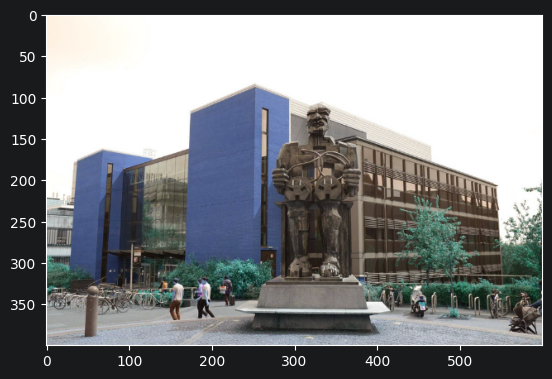

In [9]:
# Load the image and print the shape of the image

# Path to the image file
img_path = 'cs_building.png'

# Blank 1: Load the image using OpenCV's imread function
# Hint: Use cv2.imread() to read the image from the file.
img =cv2.imread(img_path)

# Blank 2: Print the shape of the image (height, width, channels)
# Hint: Use the .shape attribute of the image to print its dimensions.
print(img.shape)  # Complete the line to print the shape of the image

# Display the image using matplotlib
plt.imshow(img)

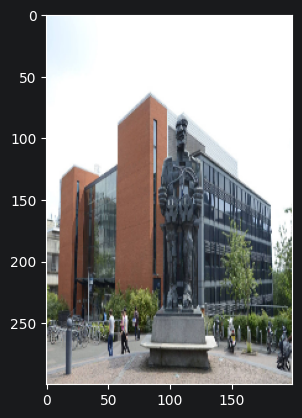

In [10]:
# Blank 3: Resize the image using OpenCV's resize function
# Hint: Use cv2.resize() to resize the image. The function takes the image and the desired dimensions (width, height) as inputs.
img_resized =cv2.resize(img, (200, 300)) # Complete the line to resize the image

# Display the resized image using matplotlib
plt.imshow(cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB))

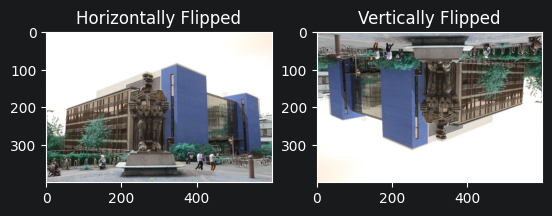

In [11]:
# Flip the image horizontally and vertically using NumPy

# Blank 4: Flip the image horizontally
# Hint: Use NumPy slicing to flip the image along the horizontal axis (flip across width).
horizontally_flipped_np = img[:, ::-1, :]    # Complete the line to flip the image horizontally

# Blank 5:  Flip the image vertically
# Hint: Use NumPy slicing to flip the image along the vertical axis (flip across height).
vertically_flipped_np =  img[::-1, :, :] # Complete the line to flip the image vertically

# Display the horizontally and vertically flipped images
plt.subplot(1, 2, 1)
plt.imshow(horizontally_flipped_np)
plt.title("Horizontally Flipped")

plt.subplot(1, 2, 2)
plt.imshow(vertically_flipped_np)
plt.title("Vertically Flipped")

plt.show()

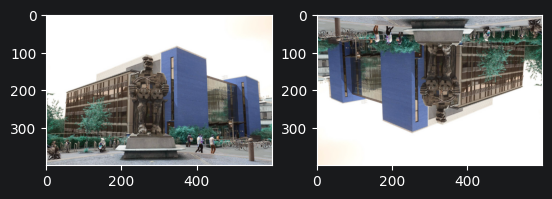

In [12]:
# Besides using NumPy, OpenCV also allows you to flip images easily.

# Flip the image horizontally and vertically using OpenCV

# Blank 6: Flip the image horizontally
# Hint: Use cv2.flip() with the specific flip code to flip the image horizontally.
horizontally_flipped =  cv2.flip(img, 1) # Complete this line

# Blank 7: Flip the image vertically
# Hint: Use cv2.flip() with the specific flip code to flip the image vertically.
vertically_flipped =  cv2.flip(img, 0)# Complete this line

# Display the horizontally and vertically flipped images
plt.subplot(1,2,1)
plt.imshow(horizontally_flipped)
plt.subplot(1,2,2)
plt.imshow(vertically_flipped)
plt.show()

## Question 1: What is the difference between the picture displayed by `plt.show` and the original picture?

Hint 1 : Image is usually composed of three channels: R (red), G (green), and B (blue). These three channels represent the color information of the image, and the value range of each channel is usually 0 to 255, which is used to represent the color intensity from the darkest to the brightest.

Hint 2 : What is the order of channels read by cv2.imread?


## Question 2: How to use `cv2` and `plt.imshow` to correctly load and display an image?

In the previous example, we used `img = cv2.imread(img_path)` to load the image. However, you may notice that the colors of the image appear incorrect, such as the building displaying unusual colors. Try to explore the reason behind it and give the correct way using `cv2` and `plt.imshow` to display the image. After this, please fill the following blank.


---

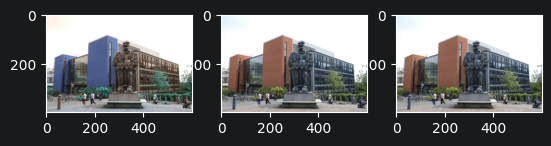

In [13]:
# Blank 8: find the correct way to read an image
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# the numpy verson of correctly reading an image
B, G, R  = img[:,:,0], img[:,:,1], img[:,:,2]
img_rgb_numpy = np.dstack((R, G, B))

plt.subplot(1,3,1)
plt.imshow(img)
plt.subplot(1,3,2)
plt.imshow(img_rgb)
plt.subplot(1,3,3)
plt.imshow(img_rgb_numpy)
plt.show()

# Part 2: PyTorch - Background Introduction

PyTorch is a powerful deep learning framework that has gained significant popularity due to its dynamic computation graph and ease of use. Learning PyTorch is essential for anyone interested in deep learning because it is widely used in both academia and industry for developing state-of-the-art models. From basic neural networks to advanced architectures like convolutional neural networks (CNNs) and recurrent neural networks (RNNs), PyTorch provides all the necessary tools to design, train, and deploy machine learning models efficiently.

### Why Learn PyTorch?

1. **Flexibility**: PyTorch's dynamic computation graph allows you to experiment with different network architectures and quickly iterate on models.
2. **Community and Ecosystem**: PyTorch has a strong community and a rich ecosystem of libraries and tools, which makes it easier to find support, resources, and pre-trained models.
3. **Industry Relevance**: Many leading tech companies and research labs use PyTorch, making it a valuable skill for a career in machine learning and AI.
4. **Ease of Use**: PyTorch’s design is intuitive, especially for those familiar with Python, and its integration with other Python libraries allows for seamless workflow management.

In this section, you will write a simple PyTorch script that defines a basic neural network, trains it on a dataset, and evaluates its performance. This exercise will help you get hands-on experience with PyTorch's core concepts, such as tensors, autograd, and the training loop.

You will:

#### 2.1 Tensor

- Learn the basics of tensors.

#### 2.2 Data Loading, Training, Optimization, and Testing

- Define a neural network using `torch.nn`.
- Train the network using a dataset like MNIST or CIFAR-10.
- Implement the training loop, including loss calculation and backpropagation.
- Evaluate the model’s performance on a validation set.

Let's get started with the exercise and see how PyTorch can be used to build and train a neural network from scratch!

### **Exercise: You will be asked to write a Simple Training Code following tutorials**




---


## 2.1 Tensors

Tensors are a specialized data structure that are very similar to arrays
and matrices. In PyTorch, we use tensors to encode the inputs and
outputs of a model, as well as the model’s parameters.

Tensors are similar to NumPy’s ndarrays, except that tensors can run on
GPUs or other specialized hardware to accelerate computing. If you’re familiar with ndarrays, you’ll
be right at home with the Tensor API. If not, follow along in this quick
API walkthrough.


In [14]:
import torch
import numpy as np

### Tensor Initialization

Tensors can be initialized in various ways. Take a look at the following examples:

**Directly from data**

Tensors can be created directly from data. The data type is automatically inferred.



In [15]:
data = [[1, 2], [3, 4]]
x_data = torch.tensor(data)

**From a NumPy array**

Tensors can be created from NumPy arrays (and vice versa - see `bridge-to-np-label`).



In [16]:
np_array = np.array(data)
x_np = torch.from_numpy(np_array)

**From another tensor:**

The new tensor retains the properties (shape, datatype) of the argument tensor, unless explicitly overridden.



In [17]:
x_ones = torch.ones_like(x_data) # retains the properties of x_data
print(f"Ones Tensor: \n {x_ones} \n")

x_rand = torch.rand_like(x_data, dtype=torch.float) # overrides the datatype of x_data
print(f"Random Tensor: \n {x_rand} \n")

Ones Tensor: 
 tensor([[1, 1],
        [1, 1]]) 

Random Tensor: 
 tensor([[0.5241, 0.1760],
        [0.1142, 0.2506]]) 



**With random or constant values:**

``shape`` is a tuple of tensor dimensions. In the functions below, it determines the dimensionality of the output tensor.



In [18]:
shape = (2, 3,)
rand_tensor = torch.rand(shape)
ones_tensor = torch.ones(shape)
zeros_tensor = torch.zeros(shape)

print(f"Random Tensor: \n {rand_tensor} \n")
print(f"Ones Tensor: \n {ones_tensor} \n")
print(f"Zeros Tensor: \n {zeros_tensor}")

Random Tensor: 
 tensor([[0.1406, 0.6105, 0.2535],
        [0.9345, 0.4808, 0.8116]]) 

Ones Tensor: 
 tensor([[1., 1., 1.],
        [1., 1., 1.]]) 

Zeros Tensor: 
 tensor([[0., 0., 0.],
        [0., 0., 0.]])


--------------




### Tensor Attributes

Tensor attributes describe their shape, datatype, and the device on which they are stored.



In [19]:
tensor = torch.rand(3, 4)

print(f"Shape of tensor: {tensor.shape}")
print(f"Datatype of tensor: {tensor.dtype}")
print(f"Device tensor is stored on: {tensor.device}")

Shape of tensor: torch.Size([3, 4])
Datatype of tensor: torch.float32
Device tensor is stored on: cpu


--------------




### Tensor Operations

Over 100 tensor operations, including transposing, indexing, slicing,
mathematical operations, linear algebra, random sampling, and more are
comprehensively described
[here](https://pytorch.org/docs/stable/torch.html)_.

Each of them can be run on the GPU (at typically higher speeds than on a
CPU). If you’re using Colab, allocate a GPU by going to Edit > Notebook
Settings.




In [20]:
# We move our tensor to the GPU if available
if torch.cuda.is_available():
  tensor = tensor.to('cuda')
  print(f"Device tensor is stored on: {tensor.device}")

Try out some of the operations from the list.
If you're familiar with the NumPy API, you'll find the Tensor API a breeze to use.




**Standard numpy-like indexing and slicing:**



In [21]:
tensor = torch.ones(4, 4)
tensor[:,1] = 0
print(tensor)

tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])


**Joining tensors** You can use ``torch.cat`` to concatenate a sequence of tensors along a given dimension.
See also [torch.stack](https://pytorch.org/docs/stable/generated/torch.stack.html)_,
another tensor joining op that is subtly different from ``torch.cat``.



In [22]:
t1 = torch.cat([tensor, tensor, tensor], dim=1)
print(t1)

tensor([[1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.],
        [1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.],
        [1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.],
        [1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.]])


**Multiplying tensors**



In [23]:
# This computes the element-wise product
print(f"tensor.mul(tensor) \n {tensor.mul(tensor)} \n")
# Alternative syntax:
print(f"tensor * tensor \n {tensor * tensor}")

tensor.mul(tensor) 
 tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]]) 

tensor * tensor 
 tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])


This computes the matrix multiplication between two tensors



In [24]:
print(f"tensor.matmul(tensor.T) \n {tensor.matmul(tensor.T)} \n")
# Alternative syntax:
print(f"tensor @ tensor.T \n {tensor @ tensor.T}")

tensor.matmul(tensor.T) 
 tensor([[3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.]]) 

tensor @ tensor.T 
 tensor([[3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.]])


--------------





### Bridge with NumPy
Tensors on the CPU and NumPy arrays can share their underlying memory
locations, and changing one will change	the other.



### Tensor to NumPy array



In [25]:
t = torch.ones(5)
print(f"t: {t}")
n = t.numpy()
print(f"n: {n}")

t: tensor([1., 1., 1., 1., 1.])
n: [1. 1. 1. 1. 1.]


### NumPy array to Tensor



In [26]:
n = np.ones(5)
t = torch.from_numpy(n)

--------------




# 2.2 Data Loading, Training, Optimization, and Testing

## 2.2.1 Load Data


Generally, when you have to deal with image, text, audio or video data,
you can use standard python packages that load data into a numpy array.
Then you can convert this array into a ``torch.*Tensor``.

-  For images, packages such as Pillow, OpenCV are useful
-  For audio, packages such as scipy and librosa
-  For text, either raw Python or Cython based loading, or NLTK and
   SpaCy are useful

Specifically for vision, we have created a package called
``torchvision``, that has data loaders for common datasets such as
ImageNet, CIFAR10, MNIST, etc. and data transformers for images, viz.,
[``torchvision.datasets``](https://pytorch.org/vision/stable/datasets.html) and ``torch.utils.data.DataLoader``.

This provides a huge convenience and avoids writing boilerplate code.

Here we will use the CIFAR10 dataset.
It has 10 classes: ‘airplane’, ‘automobile’, ‘bird’, ‘cat’, ‘deer’,
‘dog’, ‘frog’, ‘horse’, ‘ship’, ‘truck’. The images in CIFAR-10 are of
size 3x32x32, i.e. 3-channel color images of 32x32 pixels in size.


### 1. Load and normalize CIFAR10

Using ``torchvision``, it’s extremely easy to load CIFAR10.


In [27]:
import torch
import torchvision
import torchvision.transforms as transforms

The output of torchvision datasets are PILImage images of range [0, 1].
We transform them to Tensors of normalized range [-1, 1].



In [ ]:
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 4

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)

trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=1)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=1)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

31.6%

### 2. Let us show some of the training images



In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# functions to show an image


def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


# get some random training images
dataiter = iter(trainloader)
images, labels = next(dataiter)

# show images
imshow(torchvision.utils.make_grid(images))
# print labels
print(' '.join(f'{classes[labels[j]]:5s}' for j in range(batch_size)))

---

## 2.2.2 Train


### 1.Define a Convolutional Neural Network



In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 8, 3)  
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(8, 16, 3)  
        self.fc1 = nn.Linear(16 * 6 * 6, 64)  
        self.fc2 = nn.Linear(64, 10)  

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)  
        x = F.relu(self.fc1(x))
        x = self.fc2(x)  
        return x


net = Net()

### 2. Define a loss function and optimizer
Let's use a Classification Cross-Entropy loss and SGD with momentum.



In [ ]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

### 3. Train the network. 

**Here comes an exercise: Implement a Basic Training Loop in PyTorch.**

This is when things start to get interesting.

Based on the steps you've completed so far, your task is to write a training loop that trains the neural network model you've defined using the dataset you've already loaded.

**Requirements:**

- Training Loop:

Implement a training loop that runs for 1 epochs.
For each mini-batch of data, perform the following steps:
1. Forward Pass: Pass the inputs through the network to get the outputs.
2. Loss Calculation: Compute the loss using the predefined loss function (criterion).
3. Zero Gradients: Before backpropagation, ensure the gradients are zeroed using optimizer.zero_grad().
4. Backward Pass: Perform backpropagation by calling loss.backward() to compute the gradients.
5. Parameter Update: Update the model’s parameters using the optimizer (optimizer.step()).

- Output the Loss:

Track the running loss during training and print the average loss for every 2000 mini-batches to monitor the training process.
Completion Message:

After completing the 1 epochs, print a message indicating that the training is finished.


In [ ]:

epochs = 3
for epoch in range(epochs):  # loop over the dataset multiple times
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data

        # Please write the code related to zero gradienct here.
        

        # Please write the forward pass code here

        # Please write the loss calculation code here. 
        # Remember that we have chosen "criterion = nn.CrossEntropyLoss()" in the last cell

        
        # Please write the Backward Pass code here.
        # Please write the Parameter Update code here.

        # print statistics
        running_loss += loss.item()
        if i % 1000 == 1:    # print every 1000 mini-batches
            print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 1000:.3f}')
            running_loss = 0.0

print('Finished Training')


### 4. Save the trained model

In [ ]:
PATH = './cifar10_model.pth'
torch.save(net.state_dict(), PATH)

---

## 2.2.3 Test

### 1. Test the network on the test data

We have trained the network for 3 passes over the training dataset.
But we need to check if the network has learnt anything at all.

We will check this by predicting the class label that the neural network
outputs, and checking it against the ground-truth. If the prediction is
correct, we add the sample to the list of correct predictions.

Now, let's load back in our saved model (note: saving and re-loading the model wasn't necessary here, we only did it to illustrate how to do so):


In [ ]:
net = Net()
net.load_state_dict(torch.load(PATH))

Okay, now let us see what the neural network thinks these examples above are.

The outputs are energies for the 10 classes. The higher the energy for a class, the more the network thinks that the image is of the particular class. So, let's get the index of the highest energy:



In [ ]:
dataiter = iter(testloader)
images, labels = next(dataiter)

# print images
imshow(torchvision.utils.make_grid(images))
print('GroundTruth: ', ' '.join(f'{classes[labels[j]]:5s}' for j in range(4)))

outputs = net(images)

_, predicted = torch.max(outputs, 1)

print('Predicted: ', ' '.join(f'{classes[predicted[j]]:5s}'
                              for j in range(4)))

How about your resultr look like?

Let us look at how the network performs on the whole dataset.



In [ ]:
correct = 0
total = 0
# since we're not training, we don't need to calculate the gradients for our outputs
with torch.no_grad():
    for data in testloader:
        images, labels = data
        # calculate outputs by running images through the network
        outputs = net(images)
        # the class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the network on the 10000 test images: {100 * correct // total} %')

How is your network performance look like? 
Did your network learn something?



In [ ]:
# prepare to count predictions for each class
correct_pred = {classname: 0 for classname in classes}
total_pred = {classname: 0 for classname in classes}

# again no gradients needed
with torch.no_grad():
    for data in testloader:
        images, labels = data
        outputs = net(images)
        _, predictions = torch.max(outputs, 1)
        # collect the correct predictions for each class
        for label, prediction in zip(labels, predictions):
            if label == prediction:
                correct_pred[classes[label]] += 1
            total_pred[classes[label]] += 1


# print accuracy for each class
for classname, correct_count in correct_pred.items():
    accuracy = 100 * float(correct_count) / total_pred[classname]
    print(f'Accuracy for class: {classname:5s} is {accuracy:.1f} %')

---

---

### Reference

 - [Deep Learning with PyTorch: A 60 Minute Blitz](https://pytorch.org/tutorials/beginner/deep_learning_60min_blitz.html)